In [2]:
import requests
import json
import matplotlib.pyplot as plt

In [3]:
# 동영상 ID
video_id = "RvSg6kOPKKU"

get url!!!
get url finished!!!!!


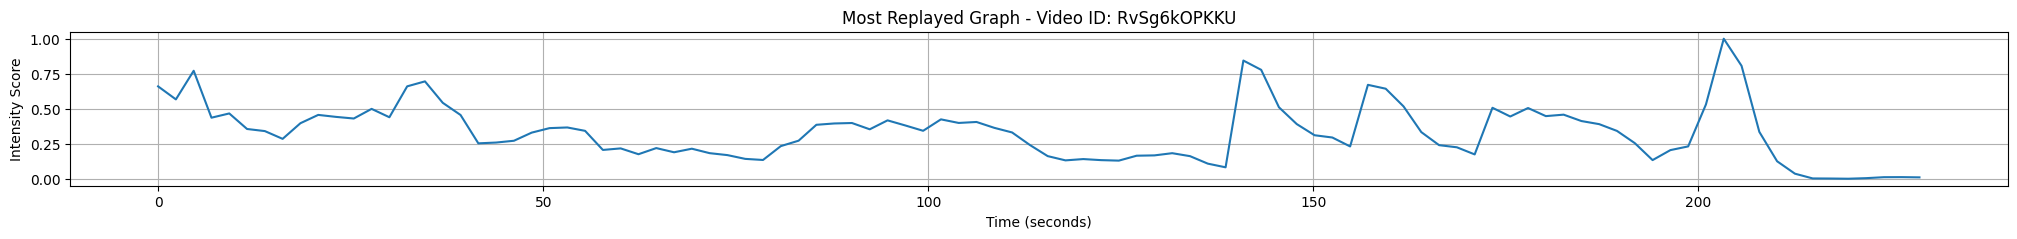

In [4]:
import requests
import json
import matplotlib.pyplot as plt



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


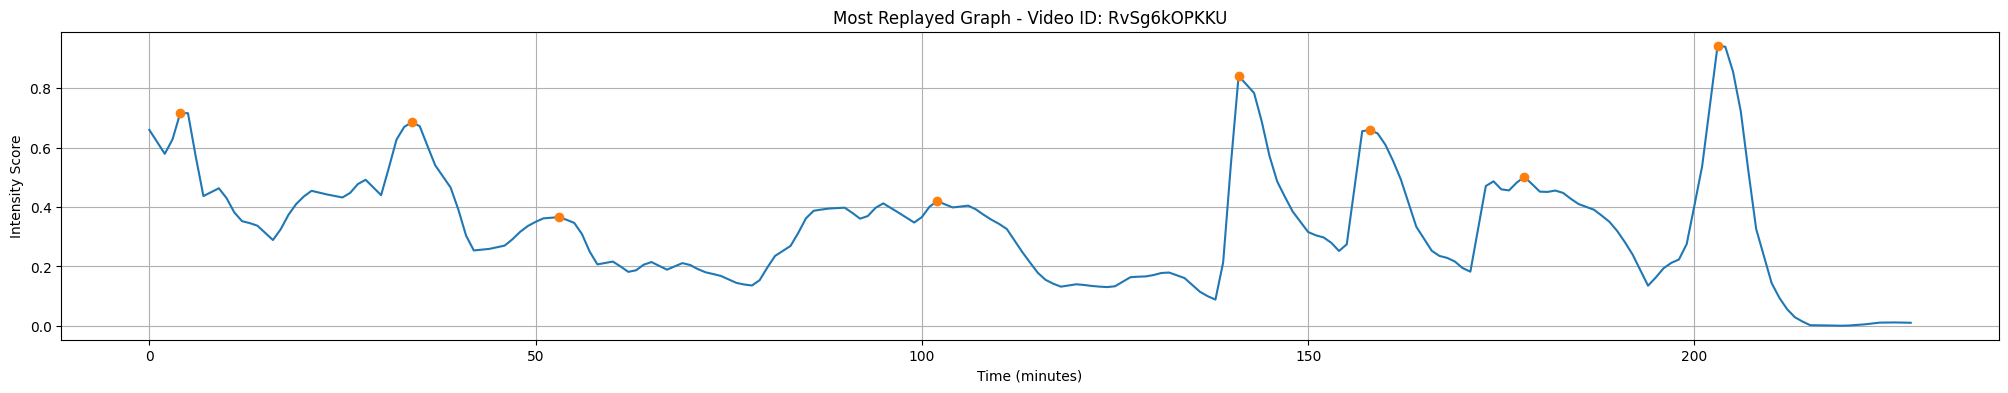

In [5]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [6]:
def find_intervals(smoothed_intensity_scores, a):
    time = np.arange(len(smoothed_intensity_scores))
    above_threshold = smoothed_intensity_scores > a
    changes = np.diff(above_threshold.astype(int))
    
    starts = time[1:][changes == 1]
    ends = time[1:][changes == -1]
    
    if above_threshold[0]:
        starts = np.insert(starts, 0, 0)
    if above_threshold[-1]:
        ends = np.append(ends, len(time) - 1)
    
    intervals = list(zip(starts, ends))
    total_time = sum(end - start for start, end in intervals)
    
    return total_time, intervals

In [7]:

def find_closest_intervals(smoothed_intensity_scores, t):
    lst = np.linspace(0, 1, 100)
    closest_diff = float('inf')
    threshold = None
    best_total_time = None
    best_intervals = None
    
    for a in lst:
        total_time, intervals = find_intervals(smoothed_intensity_scores, a)
        diff = abs(total_time - t)
        if diff < closest_diff:
            closest_diff = diff
            threshold = a
            best_total_time = total_time
            best_intervals = intervals
    
    return threshold, best_total_time, best_intervals

In [8]:
t = 45

In [9]:
threshold, total_time, threshold_intervals = find_closest_intervals(smoothed_intensity_scores, t)

In [10]:
threshold

0.4646464646464647

In [11]:
total_time

45

In [12]:
threshold_intervals

[(0, 7),
 (27, 30),
 (31, 40),
 (140, 147),
 (156, 163),
 (173, 175),
 (177, 180),
 (201, 208)]

In [13]:
lst = np.arange(0, 1, 0.01)

# 40 초가 좋아보임

for const in lst:
    total_time, intervals = find_intervals(smoothed_intensity_scores, const)
    print(const, total_time, intervals)

0.0 228 [(0, 228)]
0.01 219 [(0, 215), (224, 228)]
0.02 214 [(0, 214)]
0.03 213 [(0, 213)]
0.04 213 [(0, 213)]
0.05 213 [(0, 213)]
0.06 212 [(0, 212)]
0.07 212 [(0, 212)]
0.08 212 [(0, 212)]
0.09 211 [(0, 138), (139, 212)]
0.1 209 [(0, 137), (139, 211)]
0.11 209 [(0, 137), (139, 211)]
0.12 208 [(0, 136), (139, 211)]
0.13 208 [(0, 136), (139, 211)]
0.14 196 [(0, 77), (79, 118), (126, 135), (139, 194), (195, 211)]
0.15 192 [(0, 76), (79, 117), (127, 135), (139, 194), (195, 210)]
0.16 189 [(0, 75), (80, 116), (127, 135), (139, 194), (195, 210)]
0.17 183 [(0, 74), (80, 116), (130, 134), (139, 194), (196, 210)]
0.18 177 [(0, 73), (80, 115), (139, 194), (196, 210)]
0.19 171 [(0, 62), (64, 67), (68, 72), (80, 115), (139, 171), (172, 193), (196, 210)]
0.2 166 [(0, 61), (64, 67), (68, 71), (81, 115), (139, 170), (172, 193), (197, 210)]
0.21 161 [(0, 58), (59, 61), (65, 66), (69, 70), (81, 115), (139, 170), (172, 193), (197, 210)]
0.22 153 [(0, 58), (81, 114), (140, 169), (172, 193), (198, 210)]

In [14]:
total_time

0

In [15]:
peaks

array([  4,  34,  53, 102, 141, 158, 178, 203], dtype=int64)

In [16]:
scores = smoothed_intensity_scores


In [17]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [18]:
total_time = t

In [19]:
max_t = total_time

In [20]:
# 여ㅕ기 고침

states = [[State(time=i, count=j, score=scores[i-1]) for j in range(max_t + 1)] for i in range(1,len(scores))]


In [21]:
len(states)

228

In [22]:
min_time = 4

In [23]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [24]:
set_next_states(states, min_time, max_t)

In [25]:
states[0][0].next_states

[(1, 1)]

In [26]:
import numpy as np

def select_optimal_points(states, num_points=3):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 2), -1, dtype=int)  # 추적 테이블 수정

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                # **수정된 부분: 유효한 상태인지 확인**
                if dp[i, t, k - 1] != -np.inf:  # 유효한 상태인 경우에만 업데이트
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t)

    # 최대 점수와 마지막 인덱스 찾기
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        selected_points.append(max_index[0])
        max_index = tuple(trace[max_index[0], max_index[1], k])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score

In [27]:
def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        # if i == 162 and t == 7 and k == num_points:
                        #     pdb.set_trace()  
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace


In [28]:
def find_path(states, dp, trace, num_points=30):

    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        selected_points.append(max_index[0])
        max_index = tuple(trace[max_index[0], max_index[1], k])
        k -= 1
    
    selected_points.reverse()

    return selected_points, max_score

In [29]:
dp, trace = DP(states, num_points=total_time) 
selected_points, max_score = find_path(states, dp, trace, num_points=total_time)


In [30]:
max_score

27.477541610936285

In [31]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [32]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [33]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [34]:
# for group in grouped_points:
#     group.append(group[-1]+1)

In [35]:
grouped_points

[[1, 2, 3, 4, 5, 6],
 [27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38],
 [140, 141, 142, 143, 144, 145, 146],
 [157, 158, 159, 160, 161, 162],
 [173, 174, 175, 176, 177, 178, 179],
 [201, 202, 203, 204, 205, 206, 207]]

In [36]:
intervals = []
for elem in grouped_points:
    start = elem[0]
    end = elem[-1] + 1
    intervals.append((start, end))

In [37]:
intervals

[(1, 7), (27, 39), (140, 147), (157, 163), (173, 180), (201, 208)]

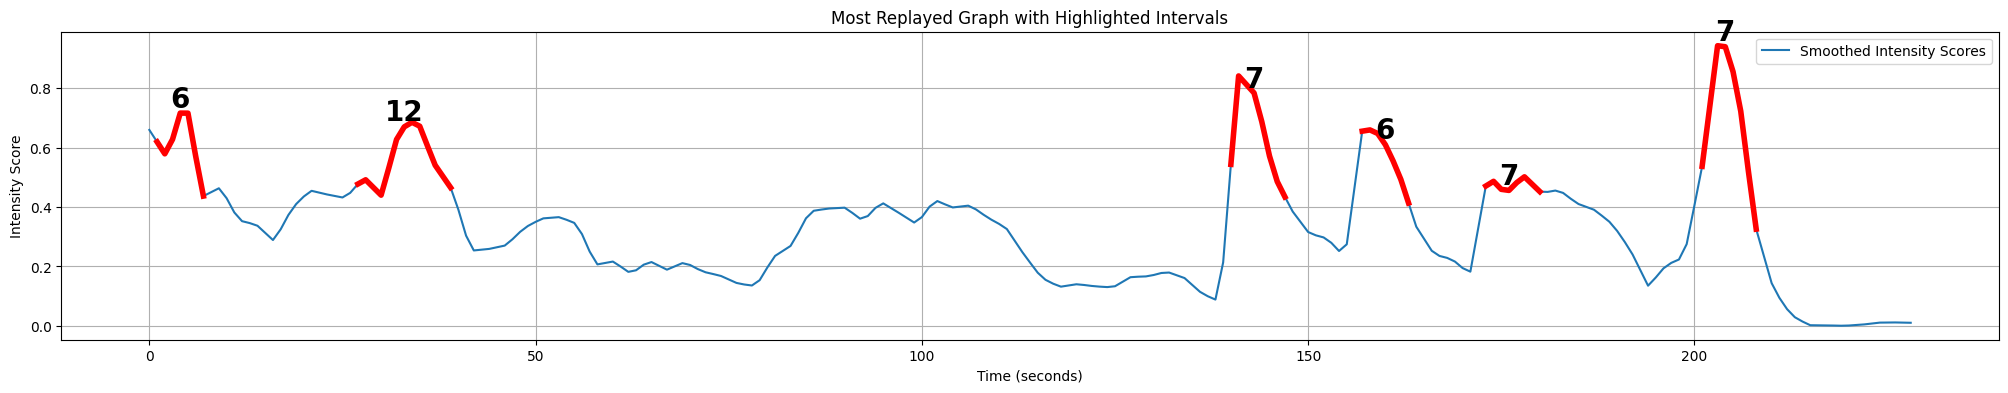

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# 가정: smoothed_intensity_scores와 start_seconds가 이미 정의되어 있음
# intervals = [(1, 7), (32, 38), (86, 114), (141, 146), (157, 162), (202, 208)]

plt.figure(figsize=(25, 4))

# 원래 그래프 그리기
plt.plot(new_time, smoothed_intensity_scores, label='Smoothed Intensity Scores')

# intervals 표시
for start, end in intervals:
    # start_seconds가 0부터 시작한다고 가정
    plt.plot(new_time[start:end+1], smoothed_intensity_scores[start:end+1], color='red', linewidth=4)
    # 점 개수 계산
    point_count = end - start 
    
    # 그룹의 중간 위치 계산
    mid_point = (start + end) // 2
    
    # 점 개수 텍스트 표시
    plt.text(new_time[mid_point], smoothed_intensity_scores[mid_point], 
             str(point_count), color='black', fontweight='bold', fontsize=20,
             ha='center', va='bottom')

plt.title('Most Replayed Graph with Highlighted Intervals')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()

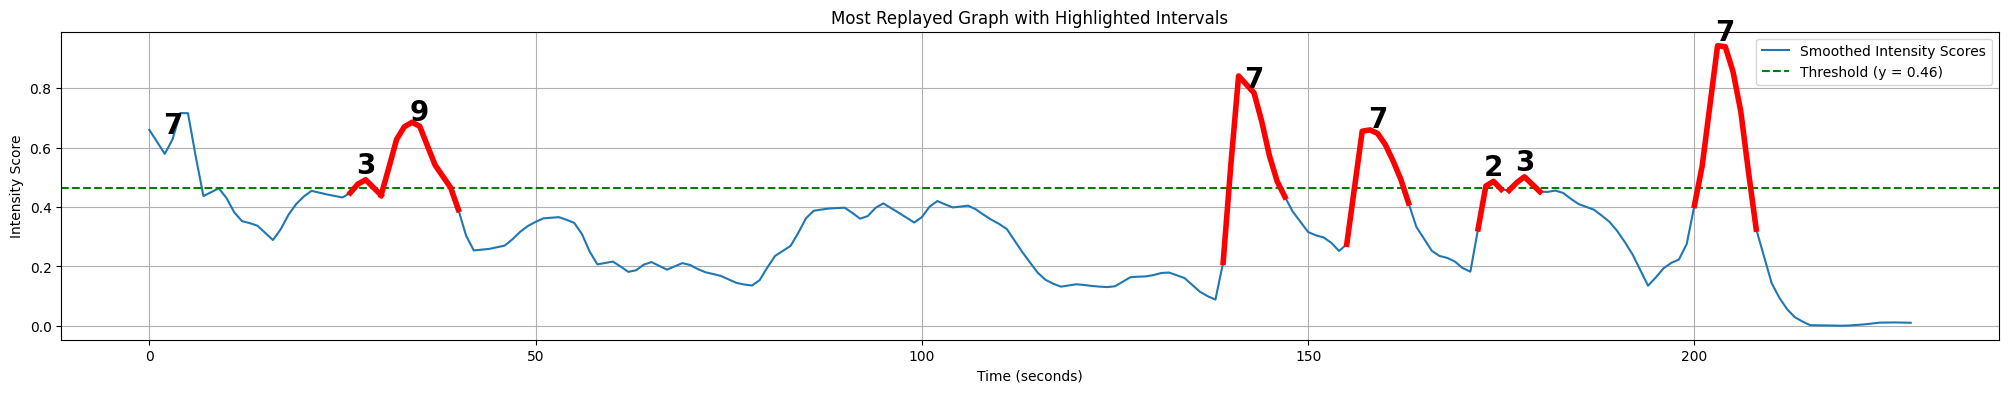

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# 가정: smoothed_intensity_scores와 start_seconds가 이미 정의되어 있음
# intervals = [(1, 7), (32, 38), (86, 114), (141, 146), (157, 162), (202, 208)]

plt.figure(figsize=(25, 4))

# 원래 그래프 그리기
plt.plot(new_time, smoothed_intensity_scores, label='Smoothed Intensity Scores')
plt.axhline(y=threshold, color='green', linestyle='--', label='Threshold (y = {:.2f})'.format(threshold))

# intervals 표시
for start, end in threshold_intervals:
    # start_seconds가 0부터 시작한다고 가정
    plt.plot(new_time[start:end+1], smoothed_intensity_scores[start:end+1], color='red', linewidth=4)
    # 점 개수 계산
    point_count = end - start 
    
    # 그룹의 중간 위치 계산
    mid_point = (start + end) // 2
    
    # 점 개수 텍스트 표시
    plt.text(new_time[mid_point], smoothed_intensity_scores[mid_point], 
             str(point_count), color='black', fontweight='bold', fontsize=20,
             ha='center', va='bottom')

plt.title('Most Replayed Graph with Highlighted Intervals')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()